# C2 — Predicting long mobilisation-to-arrival times
**Group 11:** Matías Muñoz Hoffmann and Clemente Ibarra. Business Intelligence IIB423T-1.

## Question and scope
At the moment a vehicle is mobilised, can its dispatch hour in GMT help flag a recorded mobilisation-to-arrival time of **10 minutes or longer**? One row is one vehicle mobilisation, not an incident. Positive class: `AttendanceTimeSeconds >= 600`. The cutoff is fixed and exploratory, not an official LFB standard. The intended use is a retrospective demonstration, not automated dispatch.

We continue C1 and W2. No instructor feedback on W2 had been received when this work was prepared; the W2 cleaning, fixed cutoff and chronological partitions are retained. C1/W2 already explored the full 2023–2024 dataset, so the test is a retrospective holdout, not pristine unseen future evidence. Data are from the [London Fire Brigade mobilisation records](https://data.london.gov.uk/dataset/london-fire-brigade-mobilisation-records-24r65); the saved C1 snapshot is in the project repository. December 31, 2024 is missing and durations above 20 minutes are not observed in this extract.

Only dispatch hour, known at mobilisation, is used as a predictor. Arrival, measured duration, travel and turnout times, delay codes, identifiers and geography with unverified availability are excluded. Multiple vehicles can belong to one incident; no incident may cross partitions.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, ConfusionMatrixDisplay
from IPython.display import display

root = Path.cwd().resolve()
if root.name in ('notebooks', 'analysis'): root = root.parent
source = root / 'GROUP_11_C1/data/case_tables/mobilisations_2023_2024_clean.csv.gz'
assert source.exists(), 'Run from the repository root or notebooks folder; see the source link above.'
case = pd.read_csv(source, usecols=['ResourceMobilisationId','IncidentNumber','DateAndTimeMobilised','AttendanceTimeSeconds'], dtype={'IncidentNumber':'string'})
case['timestamp'] = pd.to_datetime(case.DateAndTimeMobilised, utc=True, errors='raise')
case['hour_gmt'] = case.timestamp.dt.hour
case['target'] = (case.AttendanceTimeSeconds >= 600).astype(int)
assert len(case) == 384627 and case.ResourceMobilisationId.is_unique and case.IncidentNumber.notna().all()
print('Rows:', len(case), '| positives:',case.target.sum(), '| source cutoff: >= 600 seconds')

Rows: 384627 | positives: 26367 | source cutoff: >= 600 seconds


## W2 split and leakage protection
Training: 2023; validation: January–June 2024; test: July–December 2024. These are the actual W2 boundaries. Fixed before evaluation: one-hot encoded hour, logistic regression with class weighting, and threshold 0.5. We use validation to inspect the planned method, not to choose a new threshold. Test is evaluated once after these choices. Earlier full-data exploration prevents calling the test fully untouched.

In [2]:
train = case[case.timestamp.lt(pd.Timestamp('2024-01-01',tz='UTC'))].copy()
val = case[case.timestamp.ge(pd.Timestamp('2024-01-01',tz='UTC')) & case.timestamp.lt(pd.Timestamp('2024-07-01',tz='UTC'))].copy()
test = case[case.timestamp.ge(pd.Timestamp('2024-07-01',tz='UTC'))].copy()
parts = {'train': train, 'validation': val, 'test': test}
assert sum(len(v) for v in parts.values()) == len(case)
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert not (set(parts[a].IncidentNumber) & set(parts[b].IncidentNumber))
display(pd.DataFrame([{'partition':k,'rows':len(v),'share_pct':100*len(v)/len(case),'positive_pct':100*v.target.mean()} for k,v in parts.items()]).round(3))

,partition,rows,share_pct,positive_pct
0,train,186339,48.447,6.702
1,validation,96040,24.970,6.712
2,test,102248,26.584,7.270


## Model, baseline and validation
Logistic regression gives a simple interpretable probability based on dispatch hour. The one-hot encoder learns hour categories **from training rows only** in a scikit-learn pipeline; unknown categories are ignored. `class_weight='balanced'` compensates for the infrequent positive class. The threshold is fixed at 0.5 before inspecting validation/test results; it is illustrative, not an operational alarm threshold. The baseline always predicts the negative class, a simple comparator that can have high accuracy with rare positives. Both use the same rows. Class weighting changes the fitted loss, so its outputs are not asserted to be calibrated probabilities.

In [3]:
features=['hour_gmt']
model = Pipeline([('encode',ColumnTransformer([('hour',OneHotEncoder(handle_unknown='ignore'),features)])),
                  ('classifier',LogisticRegression(class_weight='balanced',max_iter=1000,random_state=423))])
baseline = DummyClassifier(strategy='constant',constant=0)
model.fit(train[features], train.target)
baseline.fit(train[features], train.target)
def evaluate(part, fitted, threshold=None):
    pred = (fitted.predict_proba(part[features])[:,1] >= threshold).astype(int) if threshold is not None else fitted.predict(part[features])
    y=part.target
    return {'accuracy':accuracy_score(y,pred),'precision':precision_score(y,pred,zero_division=0),
            'recall':recall_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0)}, pred
val_model,_ = evaluate(val,model,0.5)
val_base,_ = evaluate(val,baseline)
display(pd.DataFrame({'baseline':val_base,'logistic':val_model}).T.round(3))
print('Threshold fixed at 0.5; no validation-driven changes.')

,accuracy,precision,recall,f1
baseline,0.933,0.000,0.000,0.000
logistic,0.533,0.087,0.623,0.152


Threshold fixed at 0.5; no validation-driven changes.


## Final test comparison
The baseline and model are evaluated on exactly the same test records. A false negative is a >=10-minute mobilisation not flagged; a false positive is a shorter mobilisation flagged as long. A false negative could miss a case for review, while a false positive could create unnecessary review. These are hypothetical effects; this model must not be used to change dispatch. Accuracy alone is misleading when the positive class is rare. Precision is the fraction of flags that are truly positive; recall is the fraction of actual positives flagged; F1 combines them. The baseline has zero precision and recall because it never flags a positive.

,accuracy,precision,recall,f1
always negative,0.9273,0.0000,0.0000,0.0000
hour logistic,0.5370,0.0939,0.6206,0.1631


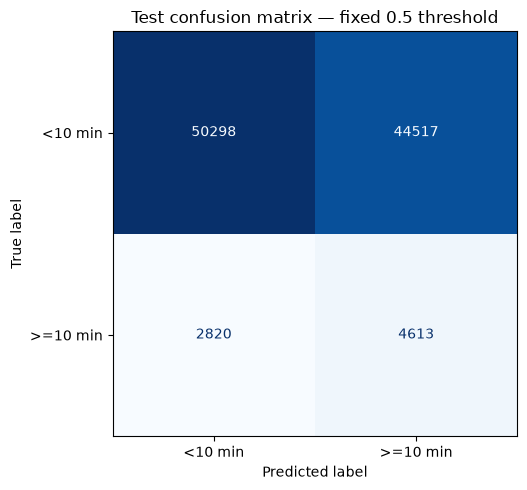

TN, FP, FN, TP: [50298, 44517, 2820, 4613]


765

In [4]:
base_metrics, base_pred=evaluate(test,baseline)
model_metrics, model_pred=evaluate(test,model,0.5)
result=pd.DataFrame({'always negative':base_metrics,'hour logistic':model_metrics}).T
display(result.round(4))
cm=confusion_matrix(test.target,model_pred,labels=[0,1])
assert cm.sum()==len(test)
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm,display_labels=['<10 min','>=10 min']).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
ax.set_title('Test confusion matrix — fixed 0.5 threshold')
fig.tight_layout(); plt.show()
print('TN, FP, FN, TP:',cm.ravel().tolist())
out=root/'outputs/c2';out.mkdir(parents=True,exist_ok=True)
fig.savefig(out/'test_confusion.png',dpi=150,bbox_inches='tight')
summary={'n_train':len(train),'n_validation':len(val),'n_test':len(test),'n_positive_test':int(test.target.sum()),'validation_baseline':val_base,'validation_model':val_model,'test_baseline':base_metrics,'test_model':model_metrics,'confusion_matrix':cm.tolist()}
(out/'results.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')

## Interpretation and next step
The saved test table and matrix quantify the trade-off between flags and missed positive cases. Compare precision, recall, F1 and accuracy to the baseline rather than treating accuracy as the sole measure. The model uses only the hour and therefore cannot account for incident distance, traffic or available resources. Its test period was already inspected in C1/W2; there is no claim of independent prospective performance or causal impact. A next step is to verify dispatch-time availability of more relevant inputs and evaluate on genuinely later data, with incident-safe boundaries and an operationally justified threshold.

## Contributions and AI assistance
Matías Muñoz Hoffmann selected the project data, discussed the fixed KPI with the instructor, and reviewed C2 data preparation, the train/validation/test split and model methodology. Clemente Ibarra reviewed the sources, confusion matrix, results and limitations, and checked that the brief and presentation agree with the notebook. Both members reviewed the final work and will prepare for the individual defense.

**AI-use disclosure.** OpenAI Codex was used as a support tool for developing the Python notebook, preparing calculations, and drafting explanations and presentation materials. This support included generating notebook code and drafts. During preparation, the notebook was executed end to end; incident separation and the confusion-matrix total were checked, and reported figures were compared with the saved results. The team reviewed the work and remains responsible for understanding and defending it without live AI during the presentation.